# Análise Exploratória — Qualidade Têxtil

Este notebook carrega as inspeções de malha (`inspecoes_malha.csv`), verifica
inconsistências artificiais no dado sintético (nulos, duplicatas, outliers, texto
inconsistente), trata o que faz sentido tratar e responde a duas perguntas
de negócio:

1. **Como defeitos e reprovações se distribuem ao longo do período?**
2. **Como as taxas de reprovação diferem entre fornecedores?**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)

## 1. Carregamento dos dados

In [2]:
df = pd.read_csv("../data/inspecoes_malha.csv")
print(f"Dimensões: {df.shape[0]} linhas x {df.shape[1]} colunas")
df.head()

Dimensões: 5000 linhas x 9 colunas


,Data,Fornecedor,Lote,Tipo de Malha,Cor,Gramatura,Torção,Defeito,Status
0,2024-01-01,Fornecedor B,LT2401-00125,PV,Vermelho,173.5,3.85,Nenhum,Aprovado
1,2024-01-01,Fornecedor C,LT2401-00369,Algodão,Preto,172.2,4.77,Nenhum,Aprovado
2,2024-01-01,Fornecedor C,LT2401-00395,Algodão,Azul Marinho,169.4,0.54,Nenhum,Aprovado
3,2024-01-01,Fornecedor E,LT2401-00685,Algodão,Amarelo,166.3,1.78,Nenhum,Aprovado
4,2024-01-01,Fornecedor E,LT2401-02517,Algodão,Branco,176.1,4.06,Nenhum,Aprovado


## 2. Verificação de inconsistências

Dado real de chão de fábrica nunca chega perfeito. Antes de qualquer
gráfico, vale checar tipos, nulos, duplicatas e valores fora do esperado.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Data           5000 non-null   object 
 1   Fornecedor     5000 non-null   object 
 2   Lote           5000 non-null   object 
 3   Tipo de Malha  5000 non-null   object 
 4   Cor            5000 non-null   object 
 5   Gramatura      4950 non-null   float64
 6   Torção         4950 non-null   float64
 7   Defeito        5000 non-null   object 
 8   Status         5000 non-null   object 
dtypes: float64(2), object(7)
memory usage: 351.7+ KB


In [4]:
print("Valores nulos por coluna:")
print(df.isnull().sum())

Valores nulos por coluna:
Data              0
Fornecedor        0
Lote              0
Tipo de Malha     0
Cor               0
Gramatura        50
Torção           50
Defeito           0
Status            0
dtype: int64


In [5]:
print("Linhas 100% idênticas (duplicata exata):", df.duplicated().sum())
print("Linhas com o mesmo Lote (duplicata de chave de negócio):", df.duplicated(subset=["Lote"]).sum())

# as duas contagens não batem -> vale investigar por quê
lotes_repetidos = df[df.duplicated(subset=["Lote"], keep=False)].sort_values("Lote")
lotes_repetidos.head(8)

Linhas 100% idênticas (duplicata exata): 18
Linhas com o mesmo Lote (duplicata de chave de negócio): 20


,Data,Fornecedor,Lote,Tipo de Malha,Cor,Gramatura,Torção,Defeito,Status
428,2024-02-03,Fornecedor A,LT2402-00721,Poliéster,Verde Musgo,153.2,5.08,Nenhum,Aprovado
446,2024-02-03,Fornecedor A,LT2402-00721,Poliéster,Verde Musgo,153.2,5.08,Nenhum,Aprovado
887,2024-03-06,Fornecedor D,LT2403-01130,Algodão,Cinza Mescla,148.1,3.52,Nenhum,Reprovado
900,2024-03-06,Fornecedor D,LT2403-01130,Algodão,Cinza Mescla,148.1,3.52,Nenhum,Reprovado
878,2024-03-05,Fornecedor C,LT2403-03671,Ribana,Bege,213.9,3.86,Nenhum,Aprovado
883,2024-03-05,Fornecedor C,LT2403-03671,Ribana,Bege,213.9,3.86,Nenhum,Aprovado
896,2024-03-06,Fornecedor A,LT2403-04570,Poliéster,Amarelo,147.1,4.47,Nenhum,Aprovado
901,2024-03-06,Fornecedor A,LT2403-04570,Poliéster,Amarelo,147.1,4.47,Nenhum,Aprovado


Repare que a duplicata **exata** (18) é menor que a duplicata por **Lote**
(20). Isso não é bug do notebook — em pelo menos um par, um nulo caiu por
acaso em só uma das duas cópias, então as linhas deixaram de ser
byte-a-byte idênticas mas continuam sendo, na prática, o mesmo lote
lançado duas vezes. Checar só `duplicated()` teria deixado 2 duplicatas
passar batido — checar pela chave de negócio (`Lote`) é o critério certo
aqui.

In [6]:
print("Valores únicos em Fornecedor:", sorted(df["Fornecedor"].unique()))
print("Valores únicos em Status:", df["Status"].unique())

Valores únicos em Fornecedor: ['Fornecedor A', 'Fornecedor B', 'Fornecedor C', 'Fornecedor D', 'Fornecedor E', 'fornecedor a', 'fornecedor b', 'fornecedor c', 'fornecedor d', 'fornecedor e']
Valores únicos em Status: ['Aprovado' 'Reprovado']


In [7]:
df["Gramatura"].describe()

count    4950.000000
mean      170.684949
std        64.122960
min       131.600000
25%       155.700000
50%       163.900000
75%       172.100000
max      2243.000000
Name: Gramatura, dtype: float64

**Resumo do que foi encontrado:**
- Algumas linhas de `Fornecedor` vieram em minúsculo (ex.: `fornecedor b`) — inconsistência de digitação manual, não um fornecedor novo.
- 20 lotes aparecem duplicados (mesmo `Lote`) — indício de dupla digitação no sistema do inspetor.
- `Gramatura` tem um valor máximo muito acima do fisicamente esperado para malha — provável vírgula decimal esquecida na digitação (ex.: 1650 em vez de 165,0).
- Há nulos em `Gramatura` e `Torção` — leituras de instrumento que não foram registradas naquele dia. Não são erro de digitação, são medições que de fato não existem; por isso não vamos inventar um valor para elas.

Um ponto que **não** é inconsistência, mas parece uma à primeira vista: existem
linhas com `Status = Reprovado` e `Defeito = Nenhum`. Isso é esperado — a peça
pode ser reprovada por sair da especificação técnica (gramatura ou torção
fora da faixa) mesmo sem apresentar defeito visual algum. O gerador também injeta reprovações sazonais sem causa registrada. Por isso, ausência de defeito visual não comprova falha técnica. O status original é preservado após a limpeza.

### 2.1 Tratamento

In [8]:
df_limpo = df.copy()

# Padroniza texto de Fornecedor (remove variação de caixa)
df_limpo["Fornecedor"] = df_limpo["Fornecedor"].str.strip().str.title()

# Remove duplicatas pela chave de negócio (Lote), não só duplicata exata
antes = len(df_limpo)
df_limpo = df_limpo.drop_duplicates(subset=["Lote"], keep="first")
print(f"Duplicatas removidas (por Lote): {antes - len(df_limpo)}")

# Corrige outlier de digitação: gramatura > 400 g/m² é fisicamente
# improvável para malha -> indício de vírgula decimal esquecida
mask_outlier = df_limpo["Gramatura"] > 400
print(f"Outliers de gramatura corrigidos: {mask_outlier.sum()}")
df_limpo.loc[mask_outlier, "Gramatura"] = df_limpo.loc[mask_outlier, "Gramatura"] / 10

# Nulos em Gramatura/Torção ficam como estão (falha real de instrumento);
# cada análise abaixo usa dropna() só na coluna que precisa
df_limpo["Data"] = pd.to_datetime(df_limpo["Data"])

print(f"\nBase tratada: {len(df_limpo)} linhas")
df_limpo.to_csv("../data/inspecoes_malha_tratada.csv", index=False, encoding="utf-8-sig")

Duplicatas removidas (por Lote): 20
Outliers de gramatura corrigidos: 6

Base tratada: 4980 linhas


## 3. Visualizações essenciais de negócio

### 3.1 Gráfico de Pareto dos defeitos

Onde concentrar esforço de correção primeiro?

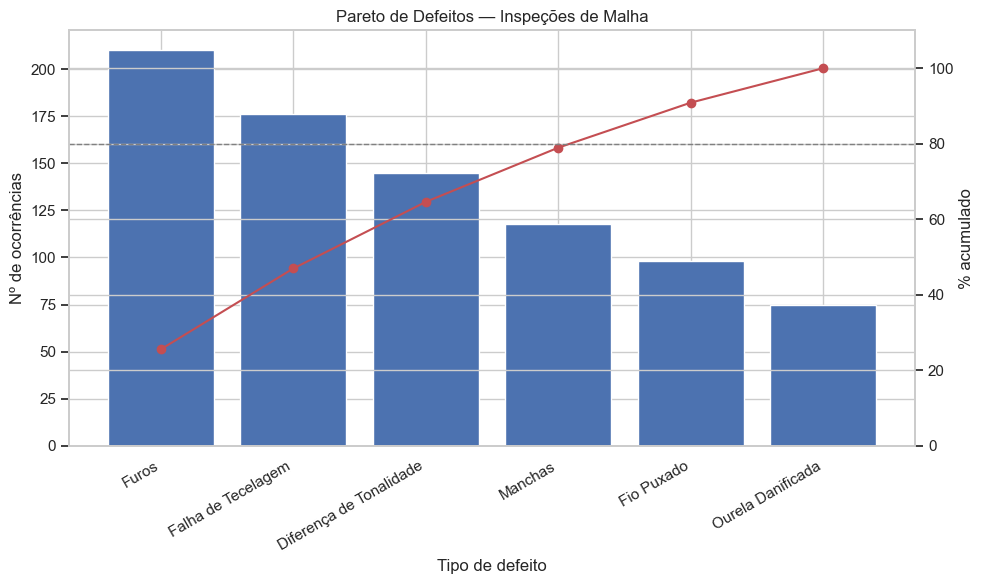

                   Defeito  Ocorrencias  Percentual_Acumulado
0                    Furos          210             25.547445
1       Falha de Tecelagem          176             46.958637
2  Diferença de Tonalidade          145             64.598540
3                  Manchas          118             78.953771
4               Fio Puxado           98             90.875912
5        Ourela Danificada           75            100.000000


In [9]:
contagem_defeitos = (
    df_limpo.loc[df_limpo["Defeito"] != "Nenhum", "Defeito"]
    .value_counts()
    .rename_axis("Defeito")
    .reset_index(name="Ocorrencias")
)
contagem_defeitos["Percentual_Acumulado"] = (
    contagem_defeitos["Ocorrencias"].cumsum() / contagem_defeitos["Ocorrencias"].sum() * 100
)

fig, ax1 = plt.subplots(figsize=(10, 6))
ax1.bar(contagem_defeitos["Defeito"], contagem_defeitos["Ocorrencias"], color="#4C72B0")
ax1.set_ylabel("Nº de ocorrências")
ax1.set_xlabel("Tipo de defeito")
plt.setp(ax1.get_xticklabels(), rotation=30, ha="right")

ax2 = ax1.twinx()
ax2.plot(contagem_defeitos["Defeito"], contagem_defeitos["Percentual_Acumulado"],
          color="#C44E52", marker="o")
ax2.set_ylabel("% acumulado")
ax2.set_ylim(0, 110)
ax2.axhline(80, color="gray", linestyle="--", linewidth=1)

plt.title("Pareto de Defeitos — Inspeções de Malha")
fig.tight_layout()
plt.savefig("../assets/pareto_defeitos.png", dpi=150, bbox_inches="tight")
plt.show()

print(contagem_defeitos)

### 3.2 Gramatura por status de aprovação

A distribuição de gramatura explica boa parte das reprovações?

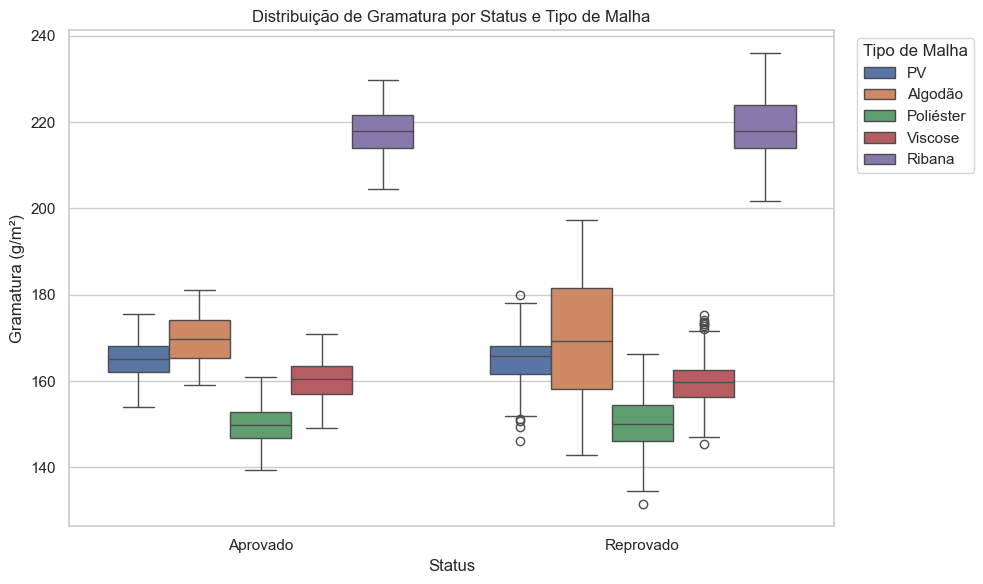

Gramatura fora da faixa técnica, por tipo de malha:
Tipo de Malha
Algodão      19.7
Poliéster     2.6
PV            2.0
Ribana        2.0
Viscose       1.9
Name: gramatura_fora_padrao, dtype: float64


In [10]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_limpo.dropna(subset=["Gramatura"]), x="Status", y="Gramatura",
            hue="Tipo de Malha")
plt.title("Distribuição de Gramatura por Status e Tipo de Malha")
plt.ylabel("Gramatura (g/m²)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Tipo de Malha")
plt.tight_layout()
plt.show()

faixa_gramatura = {
    "Algodão":   (160, 180),
    "Poliéster": (140, 160),
    "Viscose":   (150, 170),
    "PV":        (155, 175),
    "Ribana":    (205, 230),
}

def fora_da_faixa(row):
    if pd.isna(row["Gramatura"]):
        return np.nan
    baixo, alto = faixa_gramatura[row["Tipo de Malha"]]
    margem = (alto - baixo) * 0.05
    return row["Gramatura"] < (baixo - margem) or row["Gramatura"] > (alto + margem)

df_limpo["gramatura_fora_padrao"] = df_limpo.apply(fora_da_faixa, axis=1).astype("float64")
print("Gramatura fora da faixa técnica, por tipo de malha:")
print((df_limpo.groupby("Tipo de Malha")["gramatura_fora_padrao"].mean() * 100).round(1).sort_values(ascending=False))

### 3.3 Taxa de reprovação por fornecedor

Comparação descritiva das taxas dos fornecedores simulados.

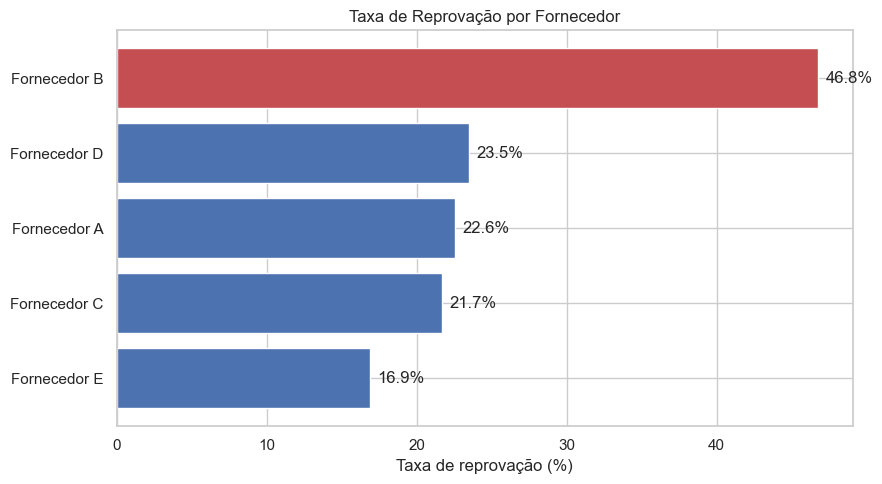

Fornecedor
Fornecedor B    46.8
Fornecedor D    23.5
Fornecedor A    22.6
Fornecedor C    21.7
Fornecedor E    16.9
Name: Status, dtype: float64


In [11]:
taxa_fornecedor = (
    df_limpo.groupby("Fornecedor")["Status"]
    .apply(lambda s: (s == "Reprovado").mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
cores_barras = ["#C44E52" if v == taxa_fornecedor.max() else "#4C72B0" for v in taxa_fornecedor.values]
plt.barh(taxa_fornecedor.index, taxa_fornecedor.values, color=cores_barras)
plt.gca().invert_yaxis()
plt.xlabel("Taxa de reprovação (%)")
plt.title("Taxa de Reprovação por Fornecedor")
for i, v in enumerate(taxa_fornecedor.values):
    plt.text(v + 0.5, i, f"{v:.1f}%", va="center")
plt.tight_layout()
plt.savefig("../assets/reprovacao_por_fornecedor.png", dpi=150, bbox_inches="tight")
plt.show()

print(taxa_fornecedor.round(1))

### 3.4 Evolução mensal da taxa de reprovação

Como as taxas mudam ao longo dos meses simulados?

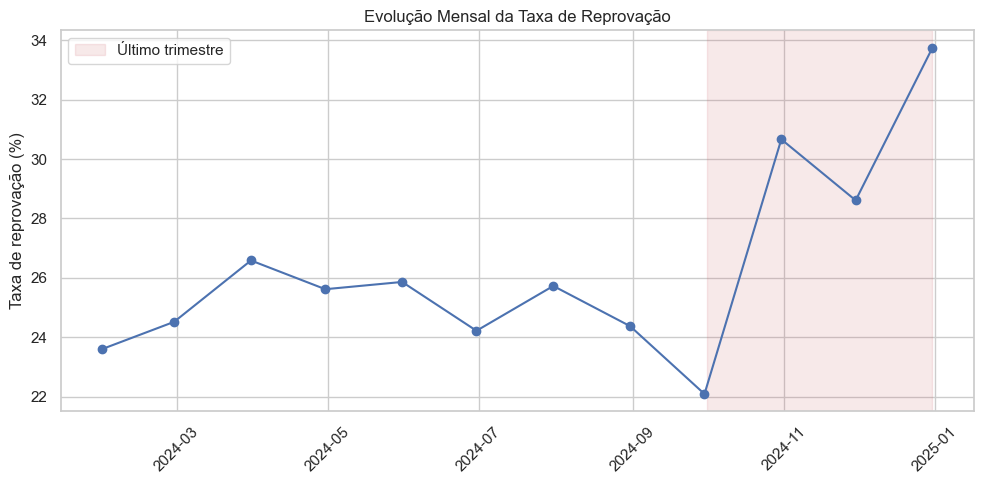

Média Jan-Set: 24.7%  |  Média Out-Dez: 31.0%


In [12]:
evolucao_mensal = (
    df_limpo.set_index("Data")
    .resample("ME")["Status"]
    .apply(lambda s: (s == "Reprovado").mean() * 100)
)

plt.figure(figsize=(10, 5))
plt.plot(evolucao_mensal.index, evolucao_mensal.values, marker="o", color="#4C72B0")
plt.axvspan(pd.Timestamp("2024-10-01"), pd.Timestamp("2024-12-31"),
            color="#C44E52", alpha=0.12, label="Último trimestre")
plt.ylabel("Taxa de reprovação (%)")
plt.title("Evolução Mensal da Taxa de Reprovação")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

media_q1_q3 = evolucao_mensal.loc[:"2024-09-30"].mean()
media_q4 = evolucao_mensal.loc["2024-10-01":].mean()
print(f"Média Jan-Set: {media_q1_q3:.1f}%  |  Média Out-Dez: {media_q4:.1f}%")

## 4. Principais achados da simulação

- Taxa geral: **26,3%**, calculada por reprovados / lotes inspecionados.
- Fornecedor B: **46,8%** de reprovação. Furos representam **40,5%** de seus defeitos visuais. Isso descreve o padrão inserido no gerador, sem comprovar causa de máquina ou manuseio.
- Fornecedor E: menor taxa anual, **16,9%**. A comparação não ajusta a composição das malhas nem justifica uma decisão real de compras.
- Algodão: **19,7%** das medições preenchidas ficam fora da faixa de gramatura; os demais tipos ficam em aproximadamente **2–3%**. A diferença foi simulada e não demonstra uma propriedade geral da fibra.
- Diferença de tonalidade representa **28,6%** dos defeitos visuais em cores escuras e **12,5%** nas demais. O denominador é o conjunto com defeito visual, não todos os lotes.
- A média simples das taxas mensais é **24,7%** em jan–set e **31,0%** em out–dez. O gerador insere esse padrão; não há dados de capacidade ou demanda para inferir gargalo.


In [13]:
taxa_geral = (df_limpo["Status"] == "Reprovado").mean() * 100

furos_fornecedor_b = (
    df_limpo.query("Fornecedor == 'Fornecedor B' and Defeito != 'Nenhum'")["Defeito"]
    .value_counts(normalize=True)
    .get("Furos", 0) * 100
)

tonalidade_escuras = df_limpo[
    df_limpo["Cor"].isin(["Preto", "Azul Marinho", "Grafite"]) & (df_limpo["Defeito"] != "Nenhum")
]["Defeito"].value_counts(normalize=True).get("Diferença de Tonalidade", 0) * 100

tonalidade_claras = df_limpo[
    ~df_limpo["Cor"].isin(["Preto", "Azul Marinho", "Grafite"]) & (df_limpo["Defeito"] != "Nenhum")
]["Defeito"].value_counts(normalize=True).get("Diferença de Tonalidade", 0) * 100

print(f"Taxa de reprovação geral: {taxa_geral:.1f}%")
print(f"Participação de 'Furos' nos defeitos do Fornecedor B: {furos_fornecedor_b:.1f}%")
print(f"'Diferença de Tonalidade' em cores escuras: {tonalidade_escuras:.1f}%  |  demais cores: {tonalidade_claras:.1f}%")

Taxa de reprovação geral: 26.3%
Participação de 'Furos' nos defeitos do Fornecedor B: 40.5%
'Diferença de Tonalidade' em cores escuras: 28.6%  |  demais cores: 12.5%


**Principais achados desta rodada de análise:**

- A taxa de reprovação geral ficou em **26,3%** no período simulado.
- O **Fornecedor B** concentra a pior performance: **46,8%** de reprovação
  (mais que o dobro do Fornecedor E). **40,5%** dos seus defeitos visuais
  são **furos** — mais que o dobro do segundo colocado (falha de
  tecelagem, 16,4%) — o que aponta para um problema pontual de
  manuseio/máquina desse fornecedor, e não do processo como um todo.
- O **Fornecedor E** é o mais confiável, com **16,9%** de reprovação —
  bom candidato a fornecedor preferencial / benchmark de processo.
- A malha de **Algodão** reprova mais, e o motivo não é visual: **19,7%**
  dos lotes de Algodão saem da faixa técnica de gramatura, contra
  **2–3%** nos demais tipos de malha — aponta para instabilidade de
  processo na fibra natural, não para um fornecedor específico.
- **Cores escuras** (Preto, Azul Marinho, Grafite) concentram mais
  "Diferença de Tonalidade": **28,6%** dos seus defeitos, contra **12,5%**
  nas demais cores — sinal de que o controle de tingimento nessas cores
  merece atenção.
- A reprovação sobe visivelmente no último trimestre: de **24,7%**
  (jan–set) para **31,0%** (out–dez) — consistente com gargalo de
  produção acelerada para a demanda de fim de ano.

## Limitações da interpretação
Os padrões são artificiais e conhecidos no gerador. Os achados acima descrevem a simulação; causas de máquina, fibra, demanda e gargalo não foram demonstradas. O ranking mensal diferente do anual não prova efeito de amostra pequena. As comparações trimestrais usam médias simples das taxas mensais. O tratamento de outliers pressupõe o erro de digitação injetado, e a deduplicação mantém a primeira ocorrência, podendo descartar uma medição preenchida na outra cópia.